In [1]:
from google.colab import files

uploaded = files.upload()

Saving Online Retail.xlsx to Online Retail.xlsx


In [2]:
['.config', 'Online Retail.xlsx', 'sample_data']

['.config', 'Online Retail.xlsx', 'sample_data']

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries imported successfully!")

df = pd.read_excel("/content/Online Retail.xlsx", nrows=10000)

print("Dataset loaded successfully!")

print("\nFIRST 10 ROWS:")
display(df.head(10))

print("\nDATASET SIZE:")
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

print("\nCOLUMN INFORMATION:")
df.info()

Libraries imported successfully!
Dataset loaded successfully!

FIRST 10 ROWS:


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
5,536365,22752,SET 7 BABUSHKA NESTING BOXES,2,2010-12-01 08:26:00,7.65,17850.0,United Kingdom
6,536365,21730,GLASS STAR FROSTED T-LIGHT HOLDER,6,2010-12-01 08:26:00,4.25,17850.0,United Kingdom
7,536366,22633,HAND WARMER UNION JACK,6,2010-12-01 08:28:00,1.85,17850.0,United Kingdom
8,536366,22632,HAND WARMER RED POLKA DOT,6,2010-12-01 08:28:00,1.85,17850.0,United Kingdom
9,536367,84879,ASSORTED COLOUR BIRD ORNAMENT,32,2010-12-01 08:34:00,1.69,13047.0,United Kingdom



DATASET SIZE:
Rows: 10000
Columns: 8

COLUMN INFORMATION:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 8 columns):
 #   Column       Non-Null Count  Dtype         
---  ------       --------------  -----         
 0   InvoiceNo    10000 non-null  object        
 1   StockCode    10000 non-null  object        
 2   Description  9958 non-null   object        
 3   Quantity     10000 non-null  int64         
 4   InvoiceDate  10000 non-null  datetime64[ns]
 5   UnitPrice    10000 non-null  float64       
 6   CustomerID   7709 non-null   float64       
 7   Country      10000 non-null  object        
dtypes: datetime64[ns](1), float64(2), int64(1), object(4)
memory usage: 625.1+ KB


In [4]:
# STEPS 10–15: DATA QUALITY ASSESSMENT

print("===== DATA QUALITY REPORT: BEFORE CLEANING =====")

# Total records
print("\nTotal Records:", len(df))

# Missing values
print("\nMissing Values:")
print(df.isnull().sum())

# Duplicate records
duplicates = df.duplicated().sum()
print("\nDuplicate Records:", duplicates)

# Cancelled transactions
cancelled = df["InvoiceNo"].astype(str).str.startswith("C").sum()
print("\nCancelled Transaction Rows:", cancelled)

# Invalid quantities
invalid_qty = (df["Quantity"] <= 0).sum()
print("\nInvalid Quantities:", invalid_qty)

# Invalid prices
invalid_price = (df["UnitPrice"] <= 0).sum()
print("\nInvalid Prices:", invalid_price)

# Column information
print("\nDataset Information:")
df.info()

print("\n===== ASSESSMENT COMPLETE =====")

===== DATA QUALITY REPORT: BEFORE CLEANING =====

Total Records: 10000

Missing Values:
InvoiceNo         0
StockCode         0
Description      42
Quantity          0
InvoiceDate       0
UnitPrice         0
CustomerID     2291
Country           0
dtype: int64

Duplicate Records: 196

Cancelled Transaction Rows: 100

Invalid Quantities: 130

Invalid Prices: 46

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 8 columns):
 #   Column       Non-Null Count  Dtype         
---  ------       --------------  -----         
 0   InvoiceNo    10000 non-null  object        
 1   StockCode    10000 non-null  object        
 2   Description  9958 non-null   object        
 3   Quantity     10000 non-null  int64         
 4   InvoiceDate  10000 non-null  datetime64[ns]
 5   UnitPrice    10000 non-null  float64       
 6   CustomerID   7709 non-null   float64       
 7   Country      10000 non-null  object        
dtypes: datetime64

In [5]:
# ==========================================
# PYTHON RETAIL DATA CLEANING
# STEPS 16–32
# ==========================================

import pandas as pd

# STEP 16: Preserve original dataset
cleaned_df = df.copy()

print("Original Records:", len(cleaned_df))

# STEP 17: Remove duplicate records
cleaned_df = cleaned_df.drop_duplicates()

print("After Removing Duplicates:", len(cleaned_df))

# STEP 18: Remove cancelled transactions
cleaned_df = cleaned_df[
    ~cleaned_df["InvoiceNo"].astype(str).str.startswith("C")
]

print("After Removing Cancellations:", len(cleaned_df))

# STEP 19: Remove invalid quantities
cleaned_df = cleaned_df[cleaned_df["Quantity"] > 0]

print("After Removing Invalid Quantities:", len(cleaned_df))

# STEP 20: Remove invalid prices
cleaned_df = cleaned_df[cleaned_df["UnitPrice"] > 0]

print("After Removing Invalid Prices:", len(cleaned_df))

# STEP 21: Remove missing product descriptions
cleaned_df = cleaned_df.dropna(subset=["Description"])

print("After Removing Missing Descriptions:", len(cleaned_df))

# STEP 22: Keep missing Customer IDs
# These may represent valid sales.

# STEP 23: Convert dates
cleaned_df["InvoiceDate"] = pd.to_datetime(
    cleaned_df["InvoiceDate"]
)

# STEP 24: Calculate total sales
cleaned_df["Total_Sales"] = (
    cleaned_df["Quantity"] * cleaned_df["UnitPrice"]
)

# STEP 25: Reset index
cleaned_df = cleaned_df.reset_index(drop=True)

# STEP 26: Compare records
original_count = len(df)
cleaned_count = len(cleaned_df)
removed_count = original_count - cleaned_count
removed_pct = (removed_count / original_count) * 100

print("\n===== CLEANING SUMMARY =====")
print("Original Records:", original_count)
print("Cleaned Records:", cleaned_count)
print("Removed Records:", removed_count)
print("Percentage Removed:", round(removed_pct, 2), "%")

# STEP 27–31: Data quality comparison
quality_report = pd.DataFrame({
    "Metric": [
        "Total Records",
        "Missing Customer IDs",
        "Missing Descriptions",
        "Cancelled Transaction Rows",
        "Invalid Quantities",
        "Invalid Prices",
        "Duplicate Records"
    ],

    "Before Cleaning": [
        len(df),
        df["CustomerID"].isnull().sum(),
        df["Description"].isnull().sum(),
        df["InvoiceNo"].astype(str).str.startswith("C").sum(),
        (df["Quantity"] <= 0).sum(),
        (df["UnitPrice"] <= 0).sum(),
        df.duplicated().sum()
    ],

    "After Cleaning": [
        len(cleaned_df),
        cleaned_df["CustomerID"].isnull().sum(),
        cleaned_df["Description"].isnull().sum(),
        cleaned_df["InvoiceNo"].astype(str).str.startswith("C").sum(),
        (cleaned_df["Quantity"] <= 0).sum(),
        (cleaned_df["UnitPrice"] <= 0).sum(),
        cleaned_df.duplicated().sum()
    ]
})

print("\n===== DATA QUALITY REPORT =====")
display(quality_report)

# STEP 32: Export cleaned data and report
cleaned_df.to_csv("cleaned_retail_data.csv", index=False)
quality_report.to_csv("data_quality_report.csv", index=False)

print("\nFiles created successfully!")
print("1. cleaned_retail_data.csv")
print("2. data_quality_report.csv")

Original Records: 10000
After Removing Duplicates: 9804
After Removing Cancellations: 9704
After Removing Invalid Quantities: 9674
After Removing Invalid Prices: 9658
After Removing Missing Descriptions: 9658

===== CLEANING SUMMARY =====
Original Records: 10000
Cleaned Records: 9658
Removed Records: 342
Percentage Removed: 3.42 %

===== DATA QUALITY REPORT =====


,Metric,Before Cleaning,After Cleaning
0,Total Records,10000,9658
1,Missing Customer IDs,2291,2246
2,Missing Descriptions,42,0
3,Cancelled Transaction Rows,100,0
4,Invalid Quantities,130,0
5,Invalid Prices,46,0
6,Duplicate Records,196,0



Files created successfully!
1. cleaned_retail_data.csv
2. data_quality_report.csv


In [6]:
# ==========================================
# PYTHON SALES ANALYSIS
# STEPS 33–42
# ==========================================

# STEP 33: Total sales
total_sales = cleaned_df["Total_Sales"].sum()

# STEP 34: Total units sold
total_units = cleaned_df["Quantity"].sum()

# STEP 35: Unique invoices
unique_invoices = cleaned_df["InvoiceNo"].nunique()

# STEP 36: Average sales per invoice
avg_sales_invoice = total_sales / unique_invoices

print("===== SALES PERFORMANCE KPIs =====")
print(f"Total Sales: £{total_sales:,.2f}")
print(f"Total Units Sold: {total_units:,}")
print(f"Unique Invoices: {unique_invoices:,}")
print(f"Average Sales per Invoice: £{avg_sales_invoice:,.2f}")

# STEP 37: Top 10 products by sales
top_sales = (
    cleaned_df.groupby("Description")["Total_Sales"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

print("\n===== TOP 10 PRODUCTS BY SALES =====")
display(top_sales)

# STEP 38: Top 10 products by quantity
top_quantity = (
    cleaned_df.groupby("Description")["Quantity"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

print("\n===== TOP 10 PRODUCTS BY QUANTITY =====")
display(top_quantity)

# STEP 39: Sales by country
sales_country = (
    cleaned_df.groupby("Country")["Total_Sales"]
    .sum()
    .sort_values(ascending=False)
)

print("\n===== SALES BY COUNTRY =====")
display(sales_country)

# STEP 40: Highest-selling country
top_country = sales_country.index[0]
top_country_sales = sales_country.iloc[0]
top_country_pct = (top_country_sales / total_sales) * 100

print("\n===== HIGHEST-SELLING COUNTRY =====")
print("Country:", top_country)
print(f"Sales: £{top_country_sales:,.2f}")
print(f"Share of Total Sales: {top_country_pct:.2f}%")

# STEP 41: Monthly sales
cleaned_df["Year_Month"] = (
    cleaned_df["InvoiceDate"].dt.to_period("M")
)

monthly_sales = (
    cleaned_df.groupby("Year_Month")["Total_Sales"]
    .sum()
)

print("\n===== MONTHLY SALES =====")
display(monthly_sales)

# STEP 42: Highest-revenue product
top_product = top_sales.index[0]
top_product_sales = top_sales.iloc[0]

print("\n===== HIGHEST-REVENUE PRODUCT =====")
print("Product:", top_product)
print(f"Sales: £{top_product_sales:,.2f}")

===== SALES PERFORMANCE KPIs =====
Total Sales: £183,529.13
Total Units Sold: 89,731
Unique Invoices: 424
Average Sales per Invoice: £432.85

===== TOP 10 PRODUCTS BY SALES =====


,Total_Sales
Description,
REGENCY CAKESTAND 3 TIER,7717.95
RED WOOLLY HOTTIE WHITE HEART.,3186.63
DOTCOM POSTAGE,2938.74
WHITE HANGING HEART T-LIGHT HOLDER,2837.93
CHILLI LIGHTS,2749.78
PAPER CHAIN KIT 50'S CHRISTMAS,2406.87
BLACK RECORD COVER FRAME,2159.79
SET 7 BABUSHKA NESTING BOXES,2022.96
ROTATING SILVER ANGELS T-LIGHT HLDR,1818.80



===== TOP 10 PRODUCTS BY QUANTITY =====


,Quantity
Description,
WORLD WAR 2 GLIDERS ASSTD DESIGNS,3409
ASSORTED COLOUR T-LIGHT HOLDER,1842
RED HARMONICA IN BOX,1660
ASSORTED INCENSE PACK,1440
WHITE HANGING HEART T-LIGHT HOLDER,1009
PACK OF 72 RETROSPOT CAKE CASES,975
ASSORTED COLOUR BIRD ORNAMENT,904
RED WOOLLY HOTTIE WHITE HEART.,829
BROCADE RING PURSE,798



===== SALES BY COUNTRY =====


,Total_Sales
Country,
United Kingdom,167651.80
Germany,3449.05
EIRE,3154.73
France,2808.16
Norway,1919.14
Lithuania,1598.06
Spain,620.00
Italy,427.80
Australia,358.25



===== HIGHEST-SELLING COUNTRY =====
Country: United Kingdom
Sales: £167,651.80
Share of Total Sales: 91.35%

===== MONTHLY SALES =====


,Total_Sales
Year_Month,
2010-12,183529.13



===== HIGHEST-REVENUE PRODUCT =====
Product: REGENCY CAKESTAND 3 TIER
Sales: £7,717.95


In [7]:
# Verify total units sold

print("Original Dataset Quantity:",
      df["Quantity"].sum())

print("Cleaned Dataset Quantity:",
      cleaned_df["Quantity"].sum())

print("Cleaned Dataset Rows:",
      len(cleaned_df))

print("Minimum Quantity:",
      cleaned_df["Quantity"].min())

print("Maximum Quantity:",
      cleaned_df["Quantity"].max())

Original Dataset Quantity: 78286
Cleaned Dataset Quantity: 89731
Cleaned Dataset Rows: 9658
Minimum Quantity: 1
Maximum Quantity: 2880


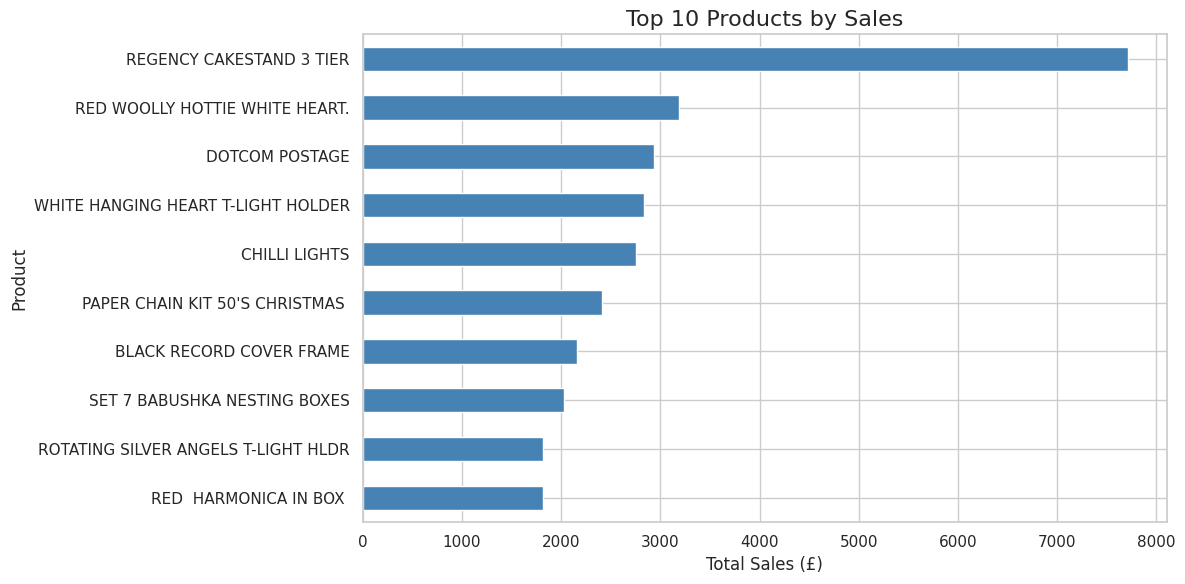

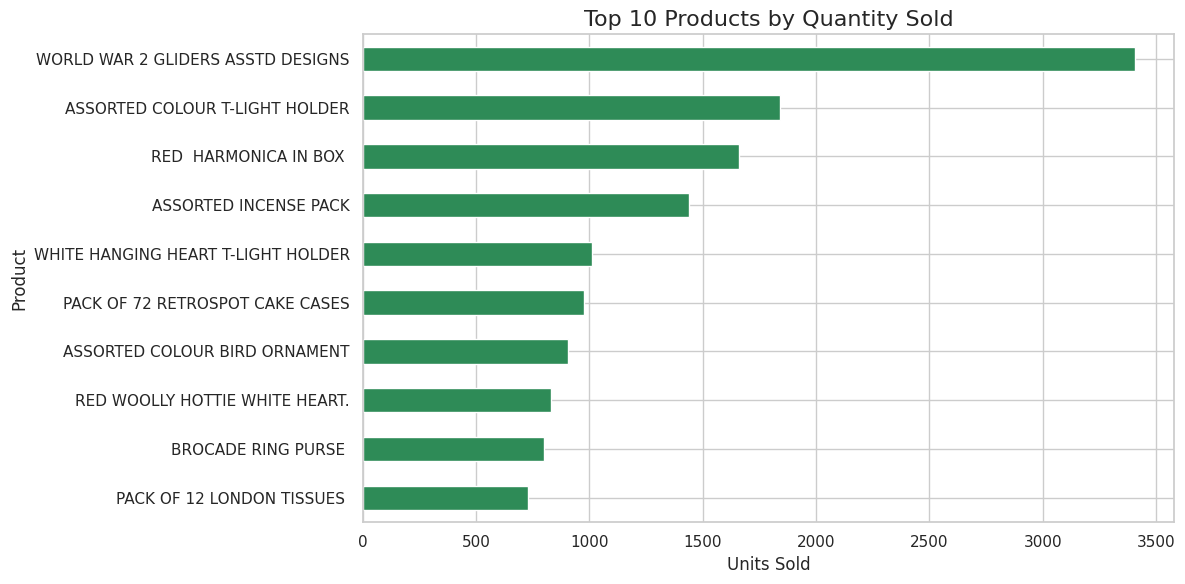

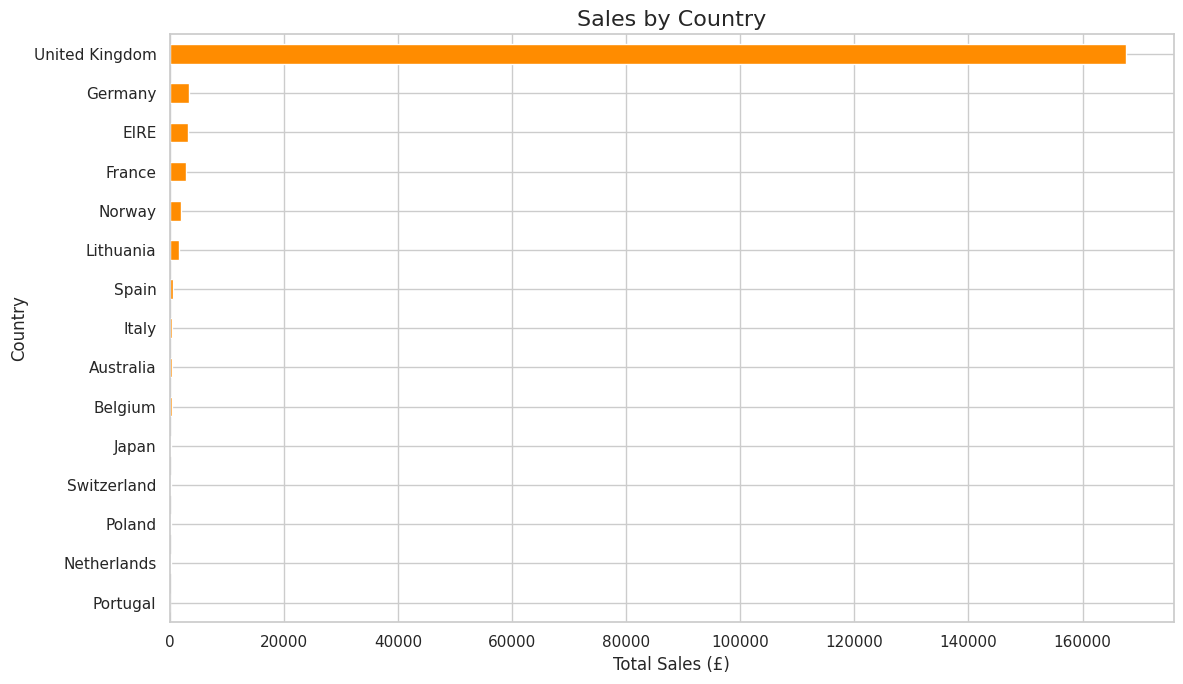

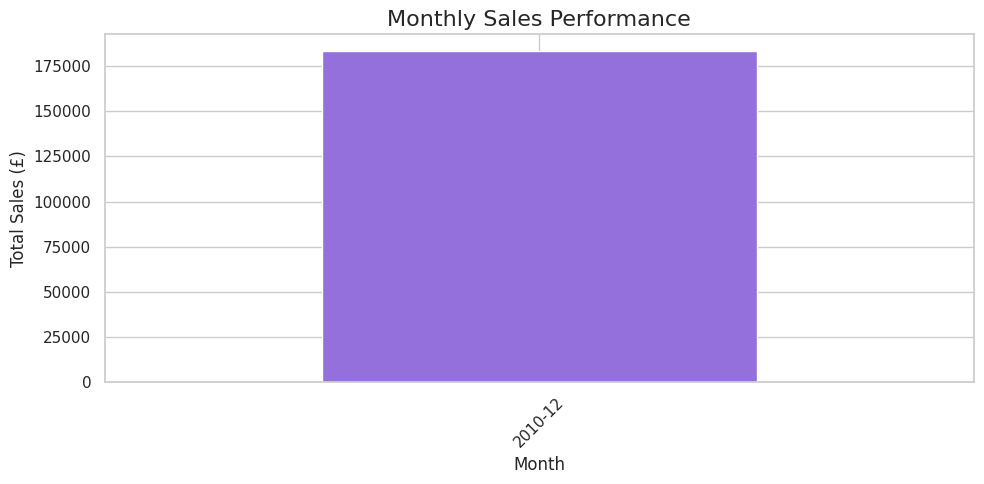

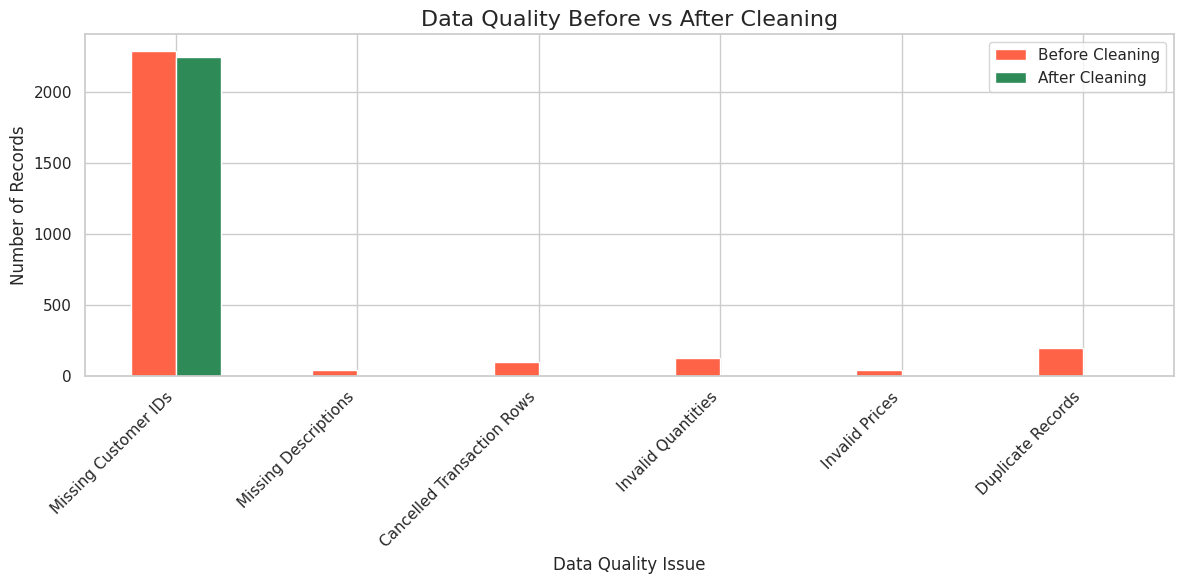


All 5 charts created successfully!
Charts saved inside the 'charts' folder.


In [8]:
# ==========================================
# PYTHON DATA VISUALIZATION
# STEPS 43–49
# ==========================================

import matplotlib.pyplot as plt
import seaborn as sns
import os

# Create a folder for charts
os.makedirs("charts", exist_ok=True)

sns.set_theme(style="whitegrid")

# CHART 1: TOP 10 PRODUCTS BY SALES

plt.figure(figsize=(12, 6))

top_sales.sort_values().plot(
    kind="barh",
    color="steelblue"
)

plt.title("Top 10 Products by Sales", fontsize=16)
plt.xlabel("Total Sales (£)")
plt.ylabel("Product")
plt.tight_layout()

plt.savefig("charts/top_products_sales.png", dpi=300)
plt.show()


# CHART 2: TOP 10 PRODUCTS BY QUANTITY

plt.figure(figsize=(12, 6))

top_quantity.sort_values().plot(
    kind="barh",
    color="seagreen"
)

plt.title("Top 10 Products by Quantity Sold", fontsize=16)
plt.xlabel("Units Sold")
plt.ylabel("Product")
plt.tight_layout()

plt.savefig("charts/top_products_quantity.png", dpi=300)
plt.show()


# CHART 3: SALES BY COUNTRY

plt.figure(figsize=(12, 7))

sales_country.sort_values().plot(
    kind="barh",
    color="darkorange"
)

plt.title("Sales by Country", fontsize=16)
plt.xlabel("Total Sales (£)")
plt.ylabel("Country")
plt.tight_layout()

plt.savefig("charts/sales_by_country.png", dpi=300)
plt.show()


# CHART 4: MONTHLY SALES

plt.figure(figsize=(10, 5))

monthly_sales.index = monthly_sales.index.astype(str)

monthly_sales.plot(
    kind="bar",
    color="mediumpurple"
)

plt.title("Monthly Sales Performance", fontsize=16)
plt.xlabel("Month")
plt.ylabel("Total Sales (£)")
plt.xticks(rotation=45)
plt.tight_layout()

plt.savefig("charts/monthly_sales.png", dpi=300)
plt.show()


# CHART 5: DATA QUALITY COMPARISON

quality_chart = quality_report[
    quality_report["Metric"] != "Total Records"
].set_index("Metric")

quality_chart.plot(
    kind="bar",
    figsize=(12, 6),
    color=["tomato", "seagreen"]
)

plt.title("Data Quality Before vs After Cleaning", fontsize=16)
plt.xlabel("Data Quality Issue")
plt.ylabel("Number of Records")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()

plt.savefig("charts/data_quality_comparison.png", dpi=300)
plt.show()

print("\nAll 5 charts created successfully!")
print("Charts saved inside the 'charts' folder.")

In [9]:
# ==========================================
# EXPORT PYTHON ANALYSIS RESULTS
# STEPS 50–54
# ==========================================

import os

# Create results folder
os.makedirs("results", exist_ok=True)

# Save cleaned dataset
cleaned_df.to_csv(
    "results/cleaned_retail_data.csv",
    index=False
)

# Save data quality report
quality_report.to_csv(
    "results/data_quality_report.csv",
    index=False
)

# Save top 10 products by sales
top_sales.to_csv(
    "results/top_10_products_sales.csv",
    header=["Total_Sales"]
)

# Save top 10 products by quantity
top_quantity.to_csv(
    "results/top_10_products_quantity.csv",
    header=["Quantity"]
)

# Save sales by country
sales_country.to_csv(
    "results/sales_by_country.csv",
    header=["Total_Sales"]
)

# Save monthly sales
monthly_sales.to_csv(
    "results/monthly_sales.csv",
    header=["Total_Sales"]
)

print("All analysis results exported successfully!")

print("\nFiles created:")
for file in os.listdir("results"):
    print("-", file)

All analysis results exported successfully!

Files created:
- monthly_sales.csv
- data_quality_report.csv
- top_10_products_sales.csv
- cleaned_retail_data.csv
- sales_by_country.csv
- top_10_products_quantity.csv


In [10]:
import shutil
from google.colab import files

# Package charts and results into one ZIP file
shutil.make_archive(
    "Python_Retail_Project_Files",
    "zip",
    ".",
    "results"
)

# Add charts to the same ZIP
import zipfile
import os

with zipfile.ZipFile(
    "Python_Retail_Project_Files.zip", "a"
) as zipf:
    for root, dirs, filenames in os.walk("charts"):
        for filename in filenames:
            filepath = os.path.join(root, filename)
            zipf.write(filepath)

# Download ZIP
files.download("Python_Retail_Project_Files.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>